# 멀티모달 RAG — 한국은행 「경제상황 평가(2026년 10월)」

- **문서**: 한국은행 보도자료 「경제상황 평가(2026년 10월)」, 21쪽 (공개 자료, bok.or.kr)
- **왜 이 문서인가**: 핵심 수치의 상당수(품목별 소비반응, 산업별 취업자수, 이전지출 구성 등)가 **본문이 아니라 차트에만** 있습니다. 텍스트만 읽는 RAG로는 답할 수 없는 질문이 생기는 문서라 멀티모달 RAG의 효과를 검증하기에 적합합니다.
- **파이프라인**: ① 파싱(텍스트·표·이미지 분리) → ② 요약(LLM/VLM) → ③ 요약으로 검색, 원본으로 답변 생성

## 0. 환경 확인

In [1]:
import shutil
import sys

print("Python:", sys.version.split()[0])
print("가상환경 경로:", sys.prefix)
print("가상환경 안에서 실행 중?", ".venv" in sys.prefix)
print()
print("Poppler  :", "OK" if shutil.which("pdftoppm") else "✗ 미설치 — Path 확인 후 재시작")
print("Tesseract:", "OK" if shutil.which("tesseract") else "✗ 미설치 — Path 확인 후 재시작")
print()
for mod in ["langchain", "unstructured", "chromadb", "tiktoken", "PIL"]:
    try:
        __import__(mod)
        print(f"{mod:14s}: OK")
    except ImportError:
        print(f"{mod:14s}: ✗ 미설치")

Python: 3.11.9
가상환경 경로: C:\workspaces\multimodal-rag\.venv
가상환경 안에서 실행 중? True

Poppler  : OK
Tesseract: OK

langchain     : OK


unstructured  : OK


chromadb      : OK
tiktoken      : OK
PIL           : OK


In [2]:
import os
import time
from pathlib import Path

from dotenv import load_dotenv

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

load_dotenv(ROOT / ".env")
if not os.getenv("OPENAI_API_KEY"):
    raise ValueError("OpenAI API 키가 없습니다. .env를 확인하세요.")

PDF_PATH = ROOT / "data" / "economy.pdf"
FIGURES_DIR = ROOT / "data" / "figures"
print("PDF:", PDF_PATH.relative_to(ROOT), PDF_PATH.exists())
print("이미지 저장 폴더:", FIGURES_DIR.relative_to(ROOT))

PDF: data\economy.pdf True
이미지 저장 폴더: data\figures


## 1. 데이터 추출 (① 문서 파싱)

`partition_pdf(strategy="hi_res")`가 레이아웃 모델로 페이지를 분석해 **텍스트 / 표 / 이미지**를 나눕니다.
한국어 문서이므로 `languages=["kor", "eng"]`로 OCR 언어를 지정했습니다. 코드: `src/extract.py`

In [3]:
from src.extract import categorize_elements, extract_pdf_elements, remove_small_images, split_texts

import pickle

# 파싱·요약 결과 캐시 (재실행 시 API 비용·시간 절약, Git 제외 폴더)
CACHE_DIR = ROOT / "data" / "processed"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
EXTRACT_CACHE = CACHE_DIR / "extracted.pkl"

if EXTRACT_CACHE.exists():
    raw_pdf_elements = pickle.loads(EXTRACT_CACHE.read_bytes())
    print("캐시에서 파싱 결과 로드")
else:
    # 이전 실행의 이미지가 섞이지 않도록 비우고 시작
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    for f in FIGURES_DIR.glob("*.jpg"):
        f.unlink()
    t0 = time.time()
    raw_pdf_elements = extract_pdf_elements(PDF_PATH, FIGURES_DIR)
    print(f"파싱 시간: {time.time() - t0:.0f}초")
    EXTRACT_CACHE.write_bytes(pickle.dumps(raw_pdf_elements))
print("요소 수:", len(raw_pdf_elements))

texts, tables = categorize_elements(raw_pdf_elements)
print("텍스트 블록:", len(texts))
print("표:", len(tables))

캐시에서 파싱 결과 로드
요소 수: 17
텍스트 블록: 12
표: 5


In [4]:
from collections import Counter
print(Counter(type(e).__name__ for e in raw_pdf_elements))

all_imgs = sorted(FIGURES_DIR.glob("*.jpg"))
print("추출된 이미지:", len(all_imgs))
removed = remove_small_images(FIGURES_DIR, min_side=150)
print(f"작은 이미지(로고·아이콘) 제거: {len(removed)}개 → {removed[:5]}")
print("남은 이미지:", len(list(FIGURES_DIR.glob('*.jpg'))))

Counter({'CompositeElement': 12, 'Table': 5})
추출된 이미지: 41
작은 이미지(로고·아이콘) 제거: 0개 → []
남은 이미지: 41


In [5]:
texts_2k_token = split_texts(texts, chunk_size=2000, chunk_overlap=200)
print("원본 블록 수:", len(texts))
print("분할 후 블록 수:", len(texts_2k_token))
print()
print(texts[0][:600])

원본 블록 수: 12
분할 후 블록 수: 20

2026년 10월 22일 공보 2026-10-17호

보 도 자 료

이 자료는 배포시부터 취급하여 주십시오.

제 목 : 경제상황 평가(2026년 10월)

□ 국내경제는 중동지역 불확실성 확대에도 반도체 경기의 강한 호조세와 여타부문으로의 파급 확산 등으로 기존 전망경로를 상회하는 높은 성장세 전망

□ 물가상승률은 누적된 비용압력이 전이되고 수요압력도 점차 확대됨에 따라 높은 수준 지속 예상

□ 전망경로에는 반도체 경기, 중동상황 등과 관련한 불확실성이 큰 상황

※ 자세한 내용은 <붙 임> 경제상황 평가(2026년 10월) 참조

[문의처 : 조사국 · 경제모형실]


In [6]:
for i, t in enumerate(tables):
    print(f"--- 표 {i} ({len(t)}자) ---")
    print(t[:400])
    print()

--- 표 0 (204자) ---
경제성장 : 조사총괄팀 차 장 이종웅 (02-759-4202), 과 장 최영우 (4167), 조사역 추성윤 (4172) 세계경제 : 국제종합팀 차 장 김보희 (4280) 경상수지 : 국제무역팀 차 장 남석모 (4190) 가 : 물가동향팀 과 장 원영진 (4220) 고용·임금 : 고용동향팀 과 장 선진산 (4205) 경제모형 : 모형전망팀 과 장 박병국 (4137)

--- 표 1 (699자) ---
(전기대비, %) 2024 연간 4/4 1/4 2/4 3/4 7월 8월 9월 GDP성장률1) 3.0 2.3 0.2 2.5 2.2 .. - - 산업생산2) -0.7 1.1 -0.5 0.3 1.2 0.7 0.2 0.1 미 소매판매 1.5 3.2 0.6 0.8 2.8 1.2 -0.4 1.3 국 소비자물가3) 2.9 2.6 2.7 2.7 3.9 3.5 3.4 3.4 비농업취업자수 증감(천명) 1,826 764 -91 130 291 130 -10 133 GDP성장률 1.3 1.2 0.2 0.0 0.6 .. - - 산업생산2) -3.0 1.8 0.1 -1.0 0.8 .. -0.3 -0.5 유 로 소매판매 1.3 2.5 0.6 0.3 0.2 .. -0.6 0.1 통관수출4) 0.6 2.5 -0.6 0.8 5.9 .. 0

--- 표 2 (180자) ---
(기간중 평균) 2024 2025 연간 4/4 1/4 2/4 3/4 2026 7월 8월 9월 10월3)- Dubai유1) 80 69 64 88 96 93 77 89 114 108 Brent유1) 80 68 63 78 97 91 84 88 102 104 유럽 천연가스2) 35 36 30 40 46 64 54 62 75 81

--- 표 3 (614자) ---
(전기대비, %) 2024 연간 4/4 1/4 2/4 GDP 성장률 2.2 1.1 -0.1 1.8 0.6 소매판매액 -1.9 0.3 0.6 2.4 -1.8 (전년동기대비) (0.9) (3.2) (2.3) 설비투자지수 3.0 1.2 -3.8 

### ✅ 체크포인트 1
- `data/figures/`에 차트 이미지가 저장됨 (아래 요약 단계에서 이미지와 요약을 함께 확인)
- `texts`, `texts_2k_token`, `tables` 모두 0보다 큼

## 2. 요약 생성 (② 요약 → 검색용 색인)

- 텍스트·표: `gpt-4o-mini` + 한국어 프롬프트 (질문도 한국어이므로 요약도 한국어로 맞춰 임베딩 공간을 일치)
- 이미지: `gpt-4o-mini`(VLM)에 Base64 이미지를 넣고 **제목·단위·계열명·기간·핵심 수치**를 포함한 한국어 요약 생성
- 코드: `src/summarize.py`

In [7]:
from src.summarize import encode_image, generate_img_summaries, generate_text_summaries

SUM_CACHE = CACHE_DIR / "text_table_summaries.pkl"
if SUM_CACHE.exists():
    text_summaries, table_summaries = pickle.loads(SUM_CACHE.read_bytes())
    print("캐시에서 요약 로드")
else:
    t0 = time.time()
    text_summaries, table_summaries = generate_text_summaries(texts_2k_token, tables, summarize_texts=True)
    print(f"요약 시간: {time.time() - t0:.0f}초")
    SUM_CACHE.write_bytes(pickle.dumps((text_summaries, table_summaries)))
print("텍스트 요약:", len(text_summaries), "/ 표 요약:", len(table_summaries))
print()
print("[text_summaries[0]]\n", text_summaries[0])
print()
if table_summaries:
    print("[table_summaries[0]]\n", table_summaries[0])

캐시에서 요약 로드
텍스트 요약: 20 / 표 요약: 5

[text_summaries[0]]
 **경제상황 평가 요약 (2026년 10월)**

- **지표 이름**: 경제상황 평가
- **기간**: 2026년 10월
- **핵심 수치**:
  - 국내경제: 반도체 경기 호조로 높은 성장세 전망
  - 물가상승률: 누적 비용압력 및 수요압력으로 높은 수준 지속 예상
  - 불확실성: 반도체 경기 및 중동상황 관련

**추가 정보**: 세계경제는 AI 투자에 힘입어 양호한 성장세를 유지할 것으로 보이며, 국제유가는 중동상황에 따라 변동하나 중장기적으로 하락할 전망.

[table_summaries[0]]
 **요약**: 

- **지표 이름**: 경제성장
- **기간**: 분기·연도
- **핵심 수치**: 조사총괄팀 차장 이종웅 (02-759-4202), 과장 최영우 (4167), 조사역 추성윤 (4172)

- **지표 이름**: 세계경제
- **기간**: 분기·연도
- **핵심 수치**: 국제종합팀 차장 김보희 (4280)

- **지표 이름**: 경상수지
- **기간**: 분기·연도
- **핵심 수치**: 국제무역팀 차장 남석모 (4190)

- **지표 이름**: 물가
- **기간**: 분기·연도
- **핵심 수치**: 물가동향팀 과장 원영진 (4220)

- **지표 이름**: 고용·임금
- **기간**: 분기·연도
- **핵심 수치**: 고용동향팀 과장 선진산 (4205)

- **지표 이름**: 경제모형
- **기간**: 분기·연도
- **핵심 수치**: 모형전망팀 과장 박병국 (4137)


In [8]:
# Base64: 그림을 '문자열 상자'에 포장 — 앞 100자만 확인
sample = sorted(FIGURES_DIR.glob("*.jpg"))[0]
print(sample.name, "→", encode_image(sample)[:100], "...")

figure-1-1.jpg → /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAx ...


In [9]:
IMG_CACHE = CACHE_DIR / "image_summaries.pkl"
if IMG_CACHE.exists():
    img_files, img_base64_list, image_summaries = pickle.loads(IMG_CACHE.read_bytes())
    print("캐시에서 이미지 요약 로드")
else:
    t0 = time.time()
    img_files, img_base64_list, image_summaries = generate_img_summaries(str(FIGURES_DIR))
    print(f"이미지 요약 시간: {time.time() - t0:.0f}초")
    IMG_CACHE.write_bytes(pickle.dumps((img_files, img_base64_list, image_summaries)))
print(f"이미지 {len(image_summaries)}개")
print()
for name, s in zip(img_files, image_summaries):
    print(f"[{name}] {s[:160]}")

캐시에서 이미지 요약 로드
이미지 41개

[figure-1-1.jpg] 이미지에는 "보도자료"라는 텍스트가 포함되어 있습니다. 이 텍스트는 특정한 데이터나 정보를 전달하는 보도자료의 제목으로 보입니다. 추가적인 데이터나 차트 정보는 포함되어 있지 않습니다.
[figure-1-2.jpg] 이미지에는 한국은행의 로고가 포함되어 있습니다. 로고는 파란색과 흰색으로 구성되어 있으며, "한국은행"과 "BANK OF KOREA"라는 텍스트가 있습니다. 로고 디자인은 현대적이고 심플하며, 금융 기관의 신뢰성을 나타냅니다.
[figure-10-20.jpg] [그림 7] 반도체 경기호조에 따른 소비 파급경로. 주요 요소로는 기업이익, 성과금·배당, 가계소득, 법인세 세수, 재정 여력, 이전지출, 정상수익, 원화가치, 실질구매력 등이 있으며, 이들 요소가 민간소비 확대에 미치는 영향을 나타냄.
[figure-10-21.jpg] [그림 8] 주요 업종의 영업이익

- 축 제목: 반도체, 자동차, 조선
- 축 단위: 조원
- 시계열: 2023, 2024, 2025, 2026 상반기
- 주요 값 및 추세:
  - 반도체: 2024년에 약 200조원으로 가장 높은 영업이익 예상
  - 자동차: 2024년에 약 20조
[figure-10-22.jpg] [그림 9] 주요 업종의 성과급 추정

- 축 제목: 업종별 성과급
- 축 단위: 조원
- 시리즈 이름: 2025, 2026, 2027
- 시간 범위: 2025-2027
- 주요 값 및 추세:
  - 반도체: 2026년 60조원 예상
  - 자동차: 2025년 4조원, 2026년 3조원
[figure-11-23.jpg] [그림 10] 소득 유형별 한계소비성향

- 축: Y축 (단위: 만원), X축 (소득 유형: 임시소득, 항상소득)
- 평균: 임시소득 11.3, 항상소득 26.0
- 주요 트렌드: 항상소득의 한계소비성향이 임시소득보다 현저히 높음.
[figure-11-24.jpg] [그림 11] 일시소득에 대한 품목별 소비반응. 축 단위

### 이미지 요약 육안 검증 (이미지와 요약을 나란히)

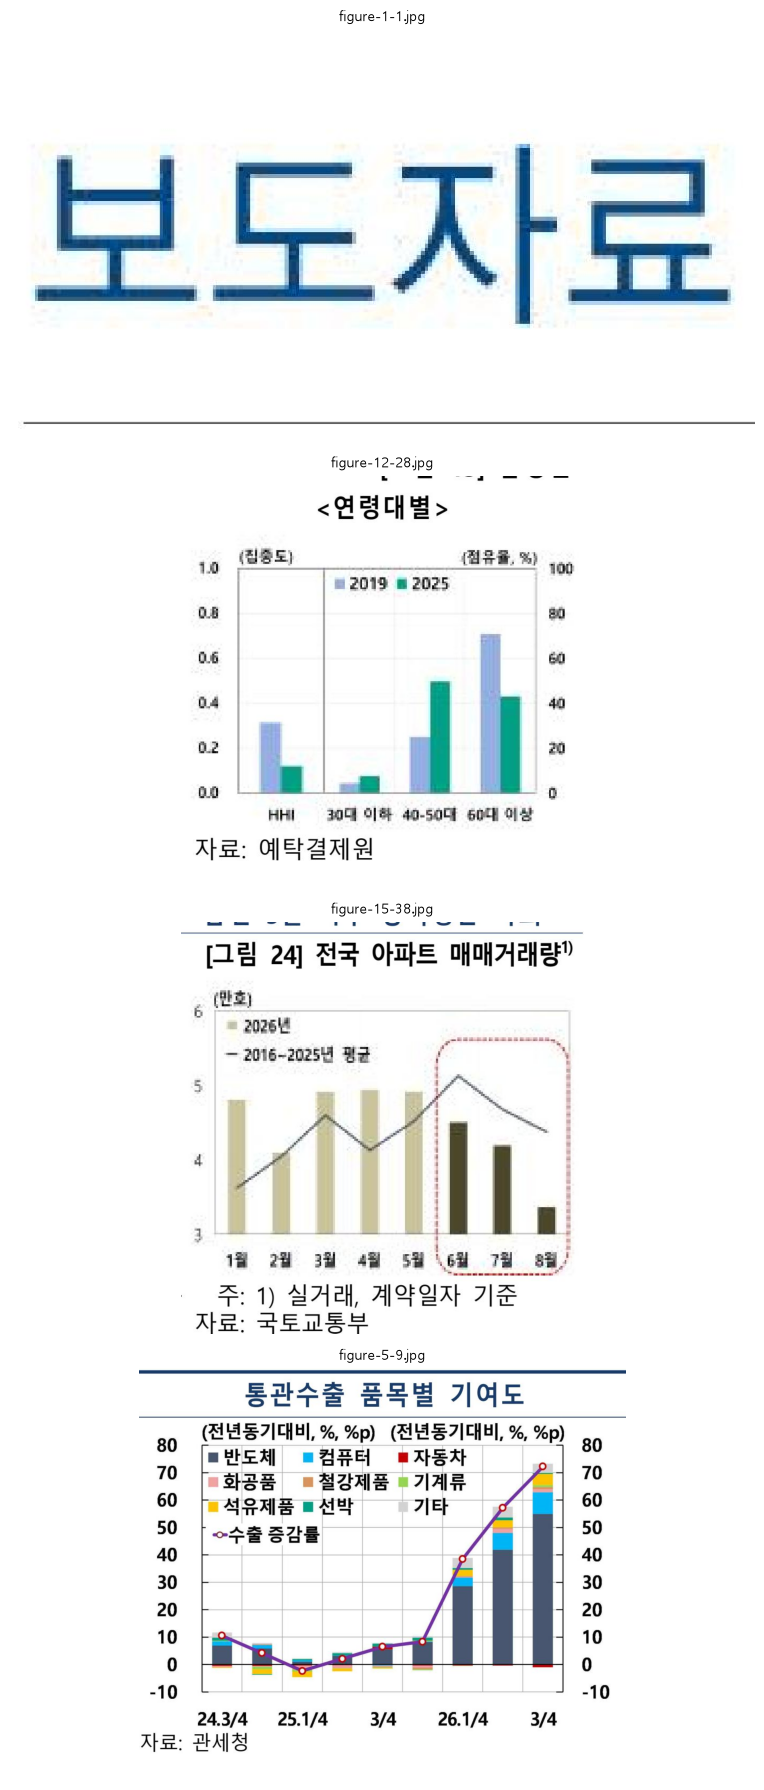

[figure-1-1.jpg]
이미지에는 "보도자료"라는 텍스트가 포함되어 있습니다. 이 텍스트는 특정한 데이터나 정보를 전달하는 보도자료의 제목으로 보입니다. 추가적인 데이터나 차트 정보는 포함되어 있지 않습니다.

[figure-12-28.jpg]
연령대별 점유율 변화 (2019-2025)

- 축: 연령대 (HHI, 30대 이하, 40-50대, 60대 이상)
- 수치: 점유율 (%)
- 시리즈: 2019 (파란색), 2025 (초록색)
- 주요 트렌드: 2025년에는 모든 연령대에서 점유율이 증가하며, 특히 60대 이상에서 가장 높은 점유율을 보임.

[figure-15-38.jpg]
[그림 24] 전국 아파트 매매거래량 요약: 

- **차트 제목**: 전국 아파트 매매거래량
- **축 단위**: 만호
- **시리즈 이름**: 2026년, 2016-2025년 평균
- **시간 범위**: 1월부터 7월까지
- **주요 값 및 추세**: 2026년 거래량은 1월 4.0만호에서 시작하여 6월에 5.5만호로 증가 후, 7월에 감소하는 경향을 보임. 2016-2025년 평균은 지속적으로 상승하는 추세.

[figure-5-9.jpg]
**통관수출 품목별 기여도**  
- **축 제목**: 전년동기대비 (%)
- **축 단위**: %
- **시리즈 이름**: 반도체, 컴퓨터, 자동차, 화공품, 철강제품, 기계류, 석유제품, 선박, 기타
- **시간 범위**: 24.3/4, 25.1/4, 26.1/4, 3/4
- **주요 값 및 추세**: 반도체와 자동차의 수출 기여도가 높으며, 전체적으로 수출 증가율이 상승하는 추세를 보임.



In [10]:
import matplotlib.pyplot as plt
from PIL import Image

plt.rcParams["font.family"] = "Malgun Gothic"
check_idx = list(range(0, len(img_files), max(1, len(img_files) // 4)))[:4]
fig, axes = plt.subplots(len(check_idx), 1, figsize=(8, 4.5 * len(check_idx)))
for ax, i in zip(axes, check_idx):
    ax.imshow(Image.open(FIGURES_DIR / img_files[i]))
    ax.axis("off")
    ax.set_title(img_files[i], fontsize=10)
plt.tight_layout()
plt.show()
for i in check_idx:
    print(f"[{img_files[i]}]\n{image_summaries[i]}\n")

## 3. 다중 벡터 검색기 (③ 요약으로 검색, 원본으로 답변)

- 벡터 저장소(요약 임베딩, `InMemoryVectorStore`) = 색인 카드 서랍, `InMemoryStore`(원본) = 서가. 둘은 같은 `doc_id`로 연결됩니다.
- 비교를 위해 **같은 구성의 텍스트 전용 검색기**(텍스트+표만 저장)도 만듭니다.
- 코드: `src/retriever.py`

In [11]:
from src.retriever import add_documents, build_multimodal_chain, create_multi_vector_retriever

mm_retriever = create_multi_vector_retriever("economy_multimodal", k=5)
add_documents(mm_retriever, text_summaries, texts_2k_token, "text")
if table_summaries:
    add_documents(mm_retriever, table_summaries, tables, "table")
add_documents(mm_retriever, image_summaries, img_base64_list, "image")

text_retriever = create_multi_vector_retriever("economy_text_only", k=5)
add_documents(text_retriever, text_summaries, texts_2k_token, "text")
if table_summaries:
    add_documents(text_retriever, table_summaries, tables, "table")

print("멀티모달 색인 수:", len(mm_retriever.vectorstore.store))
print("텍스트 전용 색인 수:", len(text_retriever.vectorstore.store))

멀티모달 색인 수: 66
텍스트 전용 색인 수: 25


In [12]:
# 검색 확인: 요약으로 찾았는데 원본(이미지 base64)이 돌아오는지
q = "배당소득 증가에 따른 품목별 소비반응"
for d in mm_retriever.vectorstore.similarity_search(q, k=4):
    print(f"[{d.metadata['kind']}] {d.page_content[:90]}")
docs = mm_retriever.invoke(q)
print()
print("반환된 원본 수:", len(docs), "| 첫 원본 앞 60자:", docs[0][:60])

[image] [그림 13] 배당소득에 대한 품목별 소비반응

- 축 제목: 품목별 소비반응 (만원)
- 주요 품목 및 소비반응:
  - 기타상품·서비스: 4.0
  - 오락문
[image] [그림 11] 일시소득에 대한 품목별 소비반응. 축 단위: 만원. 주요 품목: 생필품, 교통·운송, 음식료품, 음식숙박, 오락·문화, 교육, 의류·신발, 가사서비
[image] **통관수출 품목별 기여도**  
- **축 제목**: 전년동기대비 (%)
- **축 단위**: %
- **시리즈 이름**: 반도체, 컴퓨터, 자동차, 화공품, 
[text] **요약: 소비지출 변화 및 환율 하락의 영향 분석**

- **지표 이름**: 소비지출 변화액 및 환율 하락의 물가효과
- **기간**: 2025-2026
- 



반환된 원본 수: 5 | 첫 원본 앞 60자: /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsL


## 4. 최종 체인 & 질의응답 5건 (텍스트 RAG vs 멀티모달 RAG)

In [13]:
mm_chain = build_multimodal_chain(mm_retriever)
text_chain = build_multimodal_chain(text_retriever)

questions = [
    "배당소득이 100만원 늘어날 때 소비반응이 가장 큰 품목 3가지와 각각의 금액은?",
    "2027년 가계 이전지출 구성에서 증가 규모가 가장 큰 항목과 그 금액은?",
    "2026년 3/4분기 산업별 취업자수 증감에서 서비스업과 제조업은 각각 몇 만명인가?",
    "소비자물가와 근원물가의 3/4분기 상승률과 금년·내년 전망은?",
    "2027년 지급될 성과급 규모는 얼마로 추정되며, 업종별로는 어떻게 다른가?",
]

def evidence_kinds(retriever, q):
    return sorted({d.metadata["kind"] for d in retriever.vectorstore.similarity_search(q, k=4)})

results = []
for q in questions:
    results.append({
        "question": q,
        "text_answer": text_chain.invoke(q),
        "mm_answer": mm_chain.invoke(q),
        "mm_evidence": evidence_kinds(mm_retriever, q),
        "text_evidence": evidence_kinds(text_retriever, q),
    })

for i, r in enumerate(results, 1):
    print("=" * 100)
    print(f"Q{i}. {r['question']}")
    print(f"\n[텍스트 RAG] (근거: {', '.join(r['text_evidence'])})\n{r['text_answer']}")
    print(f"\n[멀티모달 RAG] (근거: {', '.join(r['mm_evidence'])})\n{r['mm_answer']}")

Q1. 배당소득이 100만원 늘어날 때 소비반응이 가장 큰 품목 3가지와 각각의 금액은?

[텍스트 RAG] (근거: text)
배당소득이 100만원 늘어날 때 소비반응이 가장 큰 품목 3가지와 각각의 금액은 다음과 같습니다:

1. **화장품 및 위생용품**: 5만원
2. **미용서비스**: 4만원
3. **보험서비스**: 3만원

이 정보는 [그림 13]에서 읽은 수치입니다.

[멀티모달 RAG] (근거: image, text)
배당소득이 100만원 늘어날 때 소비반응이 가장 큰 품목 3가지와 각각의 금액은 다음과 같습니다:

1. 기타상품·서비스: 4.0만원
2. 오락·문화: 3.6만원
3. 교통·운송: 3.1만원

이 데이터는 [그림 13] "배당소득에 대한 품목별 소비반응"에서 읽은 수치입니다.
Q2. 2027년 가계 이전지출 구성에서 증가 규모가 가장 큰 항목과 그 금액은?

[텍스트 RAG] (근거: text)
질문에 대한 답변은 다음과 같습니다.

2027년 가계 이전지출 구성에서 증가 규모가 가장 큰 항목은 "연금·퇴직수급자"로, 그 금액은 약 20조원 내외로 추정됩니다. 이 내용은 [그림 17]에서 확인할 수 있습니다.

[멀티모달 RAG] (근거: image, text)
2027년 가계 이전지출 구성에서 증가 규모가 가장 큰 항목은 "연금·퇴직수급지"로, 그 금액은 6.8조원입니다. 이 정보는 "[그림 17] 2027년 가계 이전지출의 구성"에서 확인할 수 있습니다.
Q3. 2026년 3/4분기 산업별 취업자수 증감에서 서비스업과 제조업은 각각 몇 만명인가?

[텍스트 RAG] (근거: table, text)
2026년 3/4분기 산업별 취업자수 증감에 대한 정보는 제공된 자료에서 확인할 수 없습니다. 따라서 서비스업과 제조업의 취업자수 증감에 대한 수치는 알 수 없습니다.

[멀티모달 RAG] (근거: image, table, text)
2026년 3/4분기 산업별 취업자수 증감에 대한 정보는 "산업별 취업자수" 차트에서 확인할 수 있습니

## 5. 번역 체인 통합 (영문 답변 → 한국어)

교안 7-5처럼 답변을 영어로 생성한 뒤 번역 체인을 뒤에 붙입니다.
로컬 Ollama에 `llama3.1:8b`가 있으면 그것을 쓰고, 없으면 `gpt-4o-mini`로 번역합니다.

In [14]:
import requests
from langchain_core.output_parsers import StrOutputParser
from src.retriever import build_translate_chain

translator = None
try:
    tags = requests.get("http://localhost:11434/api/tags", timeout=3).json()
    if any(m["name"].startswith("llama3.1") for m in tags.get("models", [])):
        from langchain_ollama.llms import OllamaLLM
        translator = OllamaLLM(model="llama3.1:8b")
except Exception:
    pass
print("번역 모델:", "Ollama llama3.1:8b" if translator else "gpt-4o-mini (Ollama 모델 없음)")

en_chain = build_multimodal_chain(mm_retriever, language="영어(English)")
final_chain = en_chain | build_translate_chain(translator)

q = questions[0]
en_answer = en_chain.invoke(q)
print("[영문 답변]\n", en_answer)
print("\n[번역]\n", build_translate_chain(translator).invoke(en_answer))

번역 모델: gpt-4o-mini (Ollama 모델 없음)


[영문 답변]
 The three items with the highest consumption response when dividend income increases by 1 million KRW, according to the chart titled "[그림 13] 배당소득에 대한 품목별 소비반응," are:

1. **기타상품·서비스** - 4.0 (10,000 KRW)
2. **오락·문화** - 3.6 (10,000 KRW)
3. **교통·운송** - 3.1 (10,000 KRW)



[번역]
 "[그림 13] 배당소득에 대한 품목별 소비반응" 차트에 따르면, 배당소득이 1,000,000 KRW 증가할 때 소비 반응이 가장 높은 세 가지 품목은 다음과 같습니다:

1. **기타상품·서비스** - 4.0 (10,000 KRW)
2. **오락·문화** - 3.6 (10,000 KRW)
3. **교통·운송** - 3.1 (10,000 KRW)


## 6. 정리
- **요약으로 검색**: 이미지는 그 자체로 임베딩 검색이 안 되므로 VLM 요약(텍스트)으로 색인합니다.
- **원본으로 답변**: 요약은 세부 수치가 빠지므로 답변 단계에서는 원본 차트 이미지·원문 텍스트를 그대로 모델에 넣습니다.
- 질의응답 결과와 텍스트 RAG 대비 차이는 README에 정리했습니다.